# 01 · Data & Preprocessing
**Owner:** Member 1

Load raw data → clean → encode/scale → split → **save splits + preprocessor** for everyone else.

In [5]:
!pip install numpy pandas scikit-learn matplotlib seaborn tensorflow

  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached six-1.17.0-py2.py3-none-any.whl.metadata (1.7 kB)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached charset_normalizer-3.5.2-cp311-cp311-win_amd64.whl.metadata (47 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached urllib3-2.8.0-py3-none-any.whl.metadata (7.4 kB)
  Using cached rich-15.0.0-py3-none-any.whl.metadata (18 kB)
  Using cached namex-0.1.0-py3-none-

In [6]:
# ===== SHARED SETUP (same in every notebook — don't change without telling the team) =====
import os, sys

# In Colab: clone the repo and move into it
if "google.colab" in sys.modules:
    REPO_URL = "https://github.com/<OWNER>/insurance-risk-scoring.git"  # <-- set once
    if not os.path.exists("insurance-risk-scoring"):
        !git clone {REPO_URL}
    %cd insurance-risk-scoring
elif os.path.basename(os.getcwd()) == "dev":
    os.chdir("../..")  # running locally from notebooks/dev

import numpy as np
import pandas as pd
import tensorflow as tf

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Paths
RAW_CSV          = "data/raw/Car_Insurance_Claim.csv"
PROCESSED_DIR    = "data/processed"
MODELS_DIR       = "models"
FIGURES_DIR      = "reports/figures"
PREPROCESSOR_PKL = f"{MODELS_DIR}/preprocessor.pkl"
BEST_MODEL       = f"{MODELS_DIR}/best_model.keras"
TARGET           = "OUTCOME"

def load_splits():
    """Load the frozen splits saved by notebook 01."""
    names = ["X_train", "X_val", "X_test", "y_train", "y_val", "y_test"]
    return [np.load(f"{PROCESSED_DIR}/{n}.npy") for n in names]

### Decisions at a glance
| Topic | Decision |
|---|---|
| Duplicates | Removed **before** splitting (exact rows, repeated IDs, identical profile + outcome). Otherwise the same customer could land in train *and* test and inflate the metrics. |
| Missing values | Rows with missing values are **removed** (`MISSING_STRATEGY = "drop"`). Set it to `"impute"` to keep them instead — the imputers inside the saved preprocessor are then fitted on **train only**. |
| Leakage | `ID` is dropped (identifier). Every other feature is audited (identifier test, target-name test, single-feature AUC) and its availability at quote time is reviewed in section 3.6. |
| Pipeline leakage | Scaler / encoders / imputers are **fitted on the training split only**, then applied to val/test (section 5). |
| Output contract | `X_*.npy`, `y_*.npy`, `class_weights.json`, `feature_names.json`, `preprocessor_meta.json` in `data/processed/`; `preprocessor.pkl` in `models/`. |

In [7]:
# ===== Notebook-01 imports & settings (NOT part of the shared setup) =====
import json, glob, shutil, warnings
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn import set_config
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.metrics import roc_auc_score
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
for d in (PROCESSED_DIR, MODELS_DIR, FIGURES_DIR):
    os.makedirs(d, exist_ok=True)

ID_COL           = "ID"
MISSING_STRATEGY = "drop"        # "drop" = remove rows with missing values | "impute" = keep, impute (train-fitted)
TEST_SIZE        = 0.15
VAL_SIZE         = 0.15          # share of the WHOLE dataset -> 70 / 15 / 15
LEAK_AUC         = 0.85          # single-feature AUC above this is "too good to be true"
DROP_SENSITIVE   = False         # True -> also drop RACE and GENDER (fairness); kept by default, see section 3.6
SENSITIVE_COLS   = ["RACE", "GENDER"]

# Ordered categories (low -> high). A column whose values don't match is automatically treated as nominal (one-hot).
ORDINAL_ORDER = {
    "AGE":                ["16-25", "26-39", "40-64", "65+"],
    "DRIVING_EXPERIENCE": ["0-9y", "10-19y", "20-29y", "30y+"],
    "EDUCATION":          ["none", "high school", "university"],
    "INCOME":             ["poverty", "working class", "middle class", "upper class"],
    "VEHICLE_YEAR":       ["before 2015", "after 2015"],
}
NOMINAL_CODES = ["POSTAL_CODE"]   # numeric-looking codes that are really categories (the number has no magnitude)
RANGE_RULES   = {"CREDIT_SCORE": (0, 1), "ANNUAL_MILEAGE": (0, None)}   # (min, max) sanity limits

def savefig(name):
    plt.tight_layout()
    plt.savefig(f"{FIGURES_DIR}/{name}", dpi=150, bbox_inches="tight")
    plt.show()

## 1. Load Data

In [8]:
def resolve_raw_csv(path=RAW_CSV):
    """Return the raw CSV path. If the file is missing, try downloading it with kagglehub (works in Colab)."""
    if os.path.exists(path):
        return path
    try:
        import kagglehub
        folder = kagglehub.dataset_download("sagnik1511/car-insurance-data")
        hits = [p for p in glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True)
                if os.path.basename(p).lower() == os.path.basename(path).lower()]
        if not hits:
            raise FileNotFoundError(f"{os.path.basename(path)} not in downloaded folder {folder}")
        os.makedirs(os.path.dirname(path), exist_ok=True)
        shutil.copy(hits[0], path)
        return path
    except Exception as e:
        raise FileNotFoundError(
            f"'{path}' not found. Download the CSV from https://www.kaggle.com/datasets/sagnik1511/car-insurance-data "
            f"and place it in data/raw/  (automatic download failed: {e})")

raw = pd.read_csv(resolve_raw_csv())
print(f"Raw data: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

Raw data: 10,000 rows x 19 columns


,ID,AGE,GENDER,RACE,DRIVING_EXPERIENCE,EDUCATION,INCOME,CREDIT_SCORE,VEHICLE_OWNERSHIP,VEHICLE_YEAR,MARRIED,CHILDREN,POSTAL_CODE,ANNUAL_MILEAGE,VEHICLE_TYPE,SPEEDING_VIOLATIONS,DUIS,PAST_ACCIDENTS,OUTCOME
0,569520,65+,female,majority,0-9y,high school,upper class,0.629027,1.0,after 2015,0.0,1.0,10238,12000.0,sedan,0,0,0,0.0
1,750365,16-25,male,majority,0-9y,none,poverty,0.357757,0.0,before 2015,0.0,0.0,10238,16000.0,sedan,0,0,0,1.0
2,199901,16-25,female,majority,0-9y,high school,working class,0.493146,1.0,before 2015,0.0,0.0,10238,11000.0,sedan,0,0,0,0.0
3,478866,16-25,male,majority,0-9y,university,working class,0.206013,1.0,before 2015,0.0,1.0,32765,11000.0,sedan,0,0,0,0.0
4,731664,26-39,male,majority,10-19y,none,working class,0.388366,1.0,before 2015,0.0,0.0,32765,12000.0,sedan,2,0,1,1.0


**Light standardisation** (no rows are removed here): trim/upper-case column names, trim/lower-case text values, turn empty strings into real missing values.

In [9]:
df = raw.copy()
df.columns = df.columns.str.strip().str.upper()
assert TARGET in df.columns, f"Target column {TARGET} not found. Columns: {list(df.columns)}"

text_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
for c in text_cols:
    df[c] = df[c].str.strip().str.lower().replace("", np.nan)

print("Text columns standardised:", text_cols)
df.info()

Text columns standardised: ['AGE', 'GENDER', 'RACE', 'DRIVING_EXPERIENCE', 'EDUCATION', 'INCOME', 'VEHICLE_YEAR', 'VEHICLE_TYPE']
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   10000 non-null  int64  
 1   AGE                  10000 non-null  str    
 2   GENDER               10000 non-null  str    
 3   RACE                 10000 non-null  str    
 4   DRIVING_EXPERIENCE   10000 non-null  str    
 5   EDUCATION            10000 non-null  str    
 6   INCOME               10000 non-null  str    
 7   CREDIT_SCORE         9018 non-null   float64
 8   VEHICLE_OWNERSHIP    10000 non-null  float64
 9   VEHICLE_YEAR         10000 non-null  str    
 10  MARRIED              10000 non-null  float64
 11  CHILDREN             10000 non-null  float64
 12  POSTAL_CODE          10000 non-null  int64  
 13  ANNUAL_MILEAGE    

## 2. EDA

### 2.1 Column types & overview

In [10]:
def infer_groups(d):
    """Split feature columns into ordinal / nominal / binary / numeric groups (ID and target excluded)."""
    feats = [c for c in d.columns if c not in (ID_COL, TARGET)]
    ordinal = {c: o for c, o in ORDINAL_ORDER.items()
               if c in feats and set(d[c].dropna().astype(str)) <= set(o)}
    rest    = [c for c in feats if c not in ordinal]
    nominal = [c for c in rest if c in NOMINAL_CODES or not pd.api.types.is_numeric_dtype(d[c])]
    binary  = [c for c in rest if c not in nominal and set(d[c].dropna().unique()) <= {0, 1}]
    numeric = [c for c in rest if c not in nominal + binary]
    return {"ordinal": ordinal, "nominal": nominal, "binary": binary, "numeric": numeric}

groups = infer_groups(df)
for k, v in groups.items():
    print(f"{k:8s}:", list(v))
fallback = [c for c in ORDINAL_ORDER if c in df.columns and c not in groups["ordinal"]]
if fallback:
    print("\n⚠️ Ordinal order does not match the data for", fallback, "-> treated as nominal (one-hot). Observed:",
          {c: sorted(df[c].dropna().unique().tolist()) for c in fallback})

overview = pd.DataFrame({"dtype": df.dtypes.astype(str), "n_unique": df.nunique(), "n_missing": df.isna().sum()})
overview

ordinal : ['AGE', 'DRIVING_EXPERIENCE', 'EDUCATION', 'INCOME', 'VEHICLE_YEAR']
nominal : ['GENDER', 'RACE', 'POSTAL_CODE', 'VEHICLE_TYPE']
binary  : ['VEHICLE_OWNERSHIP', 'MARRIED', 'CHILDREN']
numeric : ['CREDIT_SCORE', 'ANNUAL_MILEAGE', 'SPEEDING_VIOLATIONS', 'DUIS', 'PAST_ACCIDENTS']


,dtype,n_unique,n_missing
ID,int64,10000,0
AGE,str,4,0
GENDER,str,2,0
RACE,str,2,0
DRIVING_EXPERIENCE,str,4,0
EDUCATION,str,3,0
INCOME,str,4,0
CREDIT_SCORE,float64,9018,982
VEHICLE_OWNERSHIP,float64,2,0
VEHICLE_YEAR,str,2,0


In [11]:
display(df.describe().T)
display(df.describe(exclude="number").T if df.select_dtypes(exclude="number").shape[1] else "no text columns")

,count,mean,std,min,25%,50%,75%,max
ID,10000.0,500521.906800,290030.768758,101.000000,249638.500000,501777.000000,753974.500000,999976.000000
CREDIT_SCORE,9018.0,0.515813,0.137688,0.053358,0.417191,0.525033,0.618312,0.960819
VEHICLE_OWNERSHIP,10000.0,0.697000,0.459578,0.000000,0.000000,1.000000,1.000000,1.000000
MARRIED,10000.0,0.498200,0.500022,0.000000,0.000000,0.000000,1.000000,1.000000
CHILDREN,10000.0,0.688800,0.463008,0.000000,0.000000,1.000000,1.000000,1.000000
POSTAL_CODE,10000.0,19864.548400,18915.613855,10238.000000,10238.000000,10238.000000,32765.000000,92101.000000
ANNUAL_MILEAGE,9043.0,11697.003207,2818.434528,2000.000000,10000.000000,12000.000000,14000.000000,22000.000000
SPEEDING_VIOLATIONS,10000.0,1.482900,2.241966,0.000000,0.000000,0.000000,2.000000,22.000000
DUIS,10000.0,0.239200,0.554990,0.000000,0.000000,0.000000,0.000000,6.000000
PAST_ACCIDENTS,10000.0,1.056300,1.652454,0.000000,0.000000,0.000000,2.000000,15.000000


,count,unique,top,freq
AGE,10000,4,26-39,3063
GENDER,10000,2,female,5010
RACE,10000,2,majority,9012
DRIVING_EXPERIENCE,10000,4,0-9y,3530
EDUCATION,10000,3,high school,4157
INCOME,10000,4,upper class,4336
VEHICLE_YEAR,10000,2,before 2015,6967
VEHICLE_TYPE,10000,2,sedan,9523


### 2.2 Target distribution

         count   share
OUTCOME               
0.0       6867  0.6867
1.0       3133  0.3133


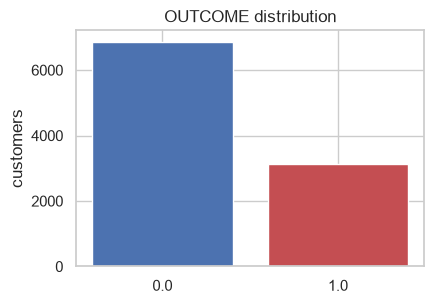

In [12]:
target_counts = df[TARGET].value_counts(dropna=False).sort_index()
print(pd.DataFrame({"count": target_counts, "share": (target_counts / len(df)).round(4)}))

fig, ax = plt.subplots(figsize=(4.5, 3.2))
ax.bar(target_counts.index.astype(str), target_counts.values, color=["#4C72B0", "#C44E52"][:len(target_counts)])
ax.set_title(f"{TARGET} distribution"); ax.set_ylabel("customers")
savefig("01_target_distribution.png")

### 2.3 Missing values (before cleaning)

,missing,pct
CREDIT_SCORE,982,9.82
ANNUAL_MILEAGE,957,9.57


Rows with at least one missing value: 1,851 (18.5% of the data)


,claim_rate_if_missing,claim_rate_if_present
CREDIT_SCORE,0.310,0.314
ANNUAL_MILEAGE,0.338,0.311


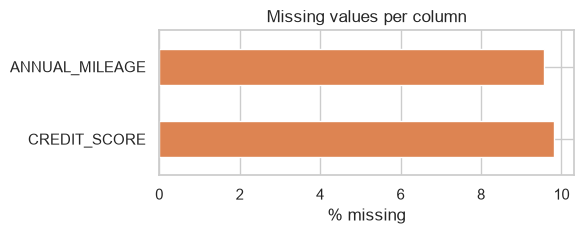

In [13]:
miss = df.isna().sum().to_frame("missing")
miss["pct"] = (miss["missing"] / len(df) * 100).round(2)
miss = miss[miss["missing"] > 0].sort_values("missing", ascending=False)

if miss.empty:
    print("No missing values.")
else:
    display(miss)
    print(f"Rows with at least one missing value: {df.isna().any(axis=1).sum():,} "
          f"({df.isna().any(axis=1).mean():.1%} of the data)")

    # Is missingness related to the outcome? (if the claim rates differ a lot, dropping rows would bias the data)
    rel = pd.DataFrame({
        c: {"claim_rate_if_missing": df.loc[df[c].isna(), TARGET].mean(),
            "claim_rate_if_present": df.loc[df[c].notna(), TARGET].mean()}
        for c in miss.index}).T.round(3)
    display(rel)

    ax = miss["pct"].plot.barh(figsize=(6, 0.5 * len(miss) + 1.5), color="#DD8452")
    ax.set_xlabel("% missing"); ax.set_title("Missing values per column")
    savefig("02_missing_values.png")

### 2.4 Numeric feature distributions (by outcome)

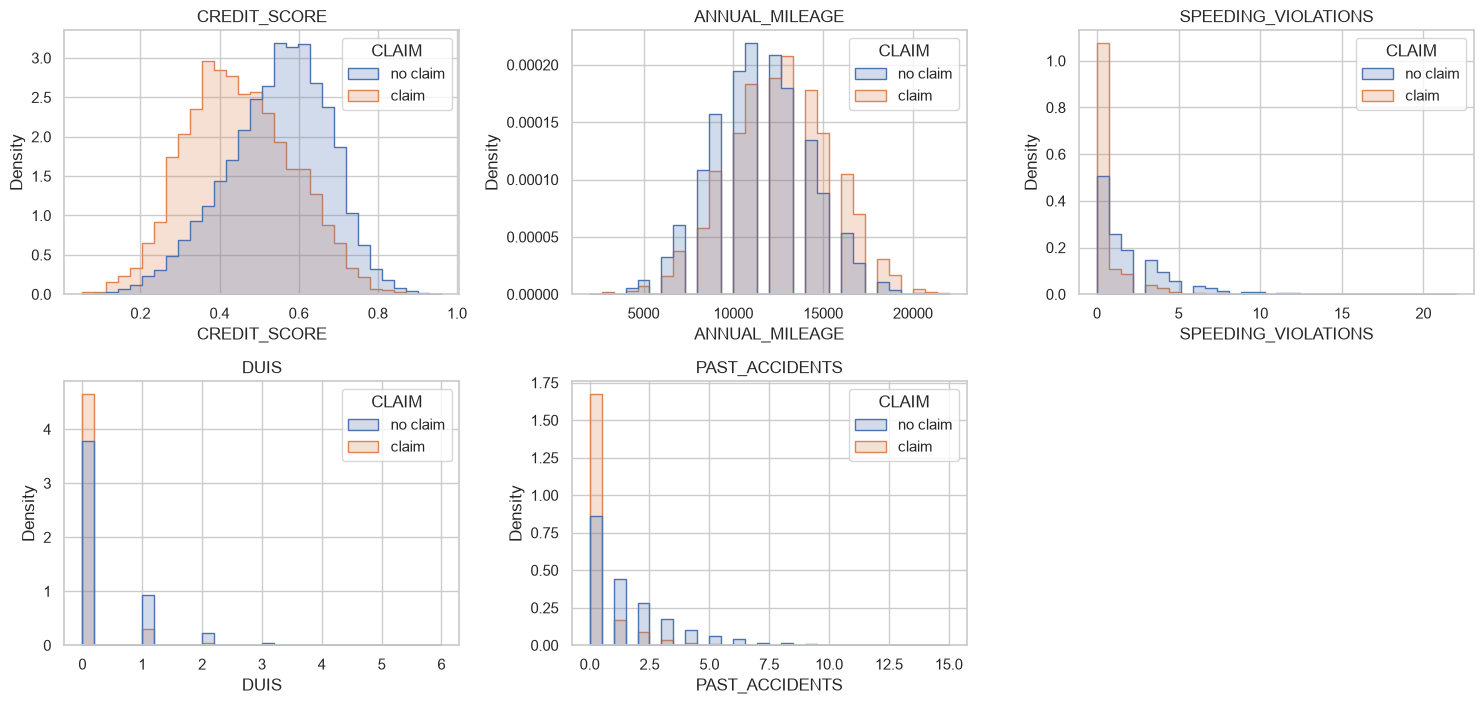

In [14]:
num_cols = groups["numeric"]
if num_cols:
    tmp = df.assign(CLAIM=df[TARGET].map({0: "no claim", 1: "claim"}))
    ncols = min(3, len(num_cols)); nrows = int(np.ceil(len(num_cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.6 * nrows), squeeze=False)
    for ax, c in zip(axes.ravel(), num_cols):
        sns.histplot(data=tmp, x=c, hue="CLAIM", bins=30, element="step", stat="density", common_norm=False, ax=ax)
        ax.set_title(c)
    for ax in axes.ravel()[len(num_cols):]:
        ax.set_visible(False)
    savefig("03_numeric_distributions.png")

### 2.5 Claim rate by category

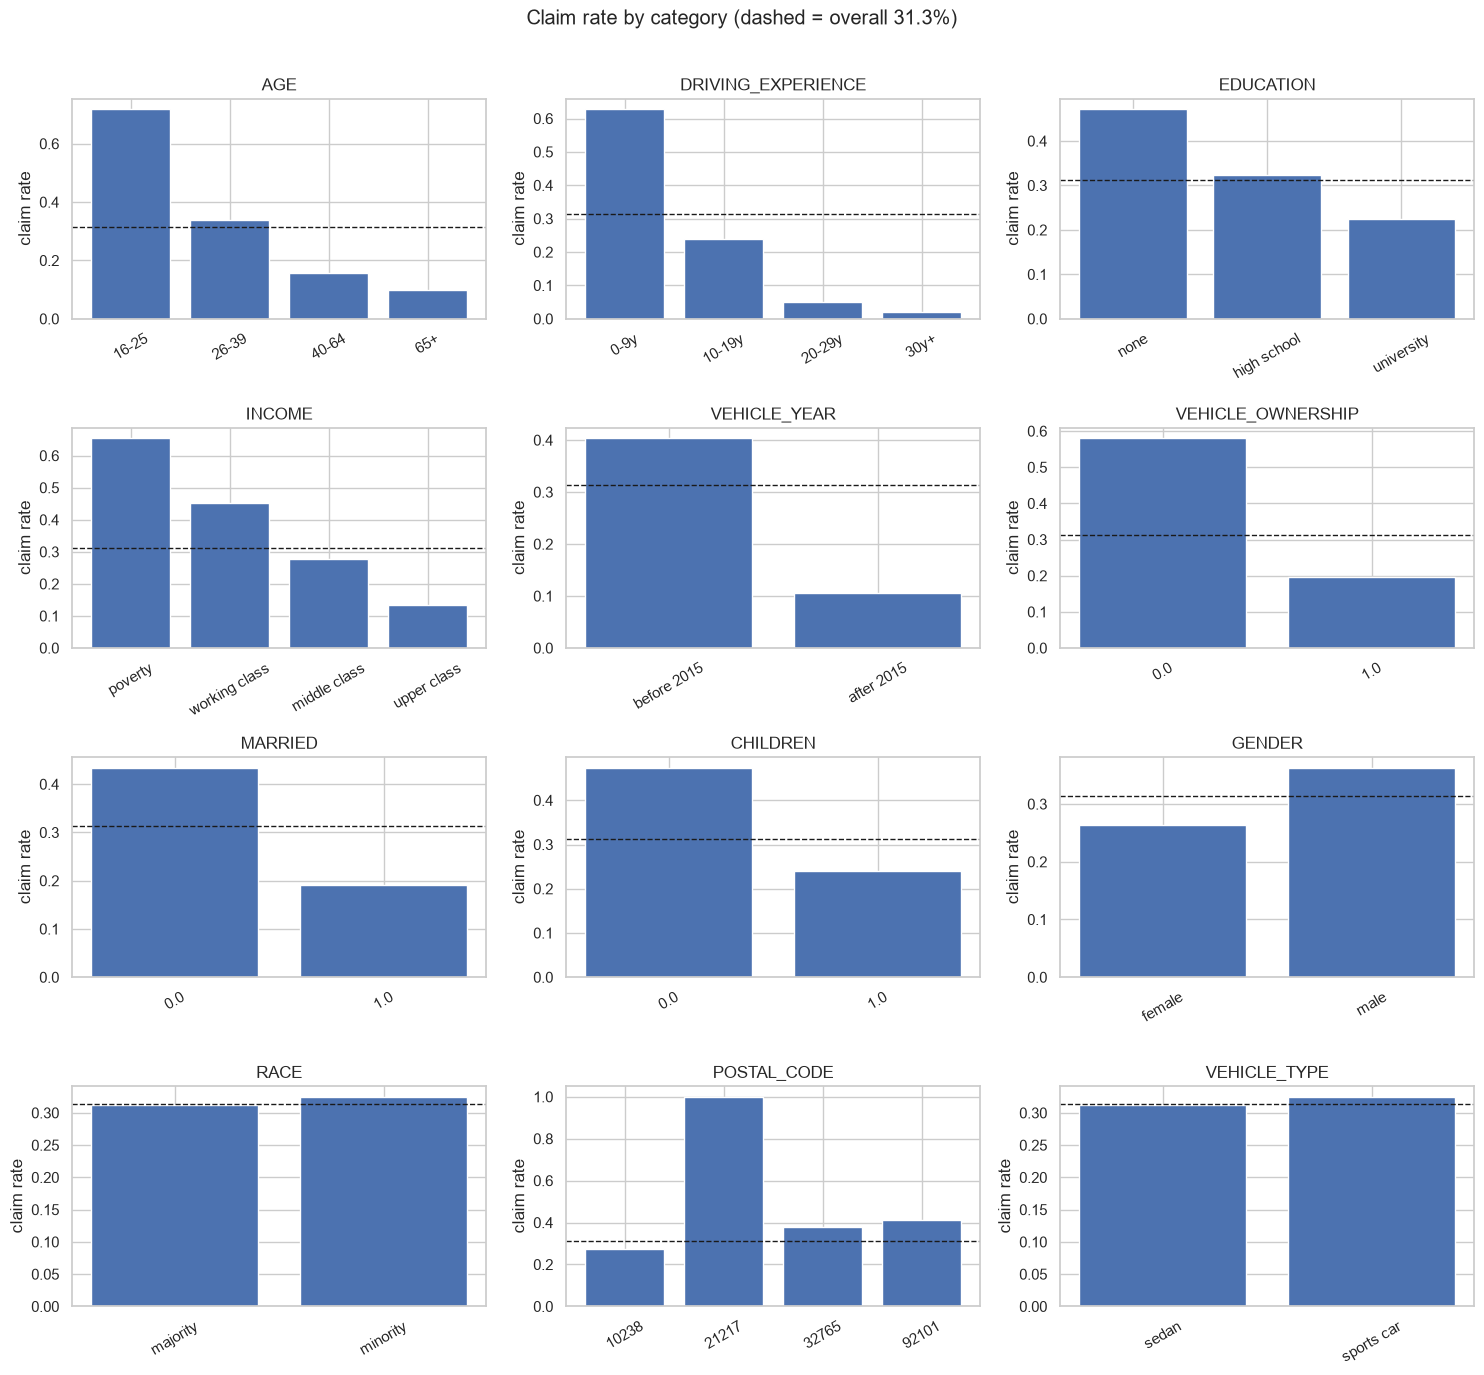

In [15]:
cat_cols = list(groups["ordinal"]) + groups["binary"] + groups["nominal"]
overall = df[TARGET].mean()
ncols = 3; nrows = int(np.ceil(len(cat_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.4 * nrows), squeeze=False)
for ax, c in zip(axes.ravel(), cat_cols):
    rate = df.groupby(c)[TARGET].mean()
    if c in groups["ordinal"]:
        rate = rate.reindex([k for k in groups["ordinal"][c] if k in rate.index])
    ax.bar(rate.index.astype(str), rate.values, color="#4C72B0")
    ax.axhline(overall, ls="--", c="k", lw=1)
    ax.set_title(c); ax.set_ylabel("claim rate"); ax.tick_params(axis="x", rotation=30)
for ax in axes.ravel()[len(cat_cols):]:
    ax.set_visible(False)
fig.suptitle(f"Claim rate by category (dashed = overall {overall:.1%})", y=1.01)
savefig("04_claim_rate_by_category.png")

### 2.6 Correlations (Spearman, ordinal features coded by their order)

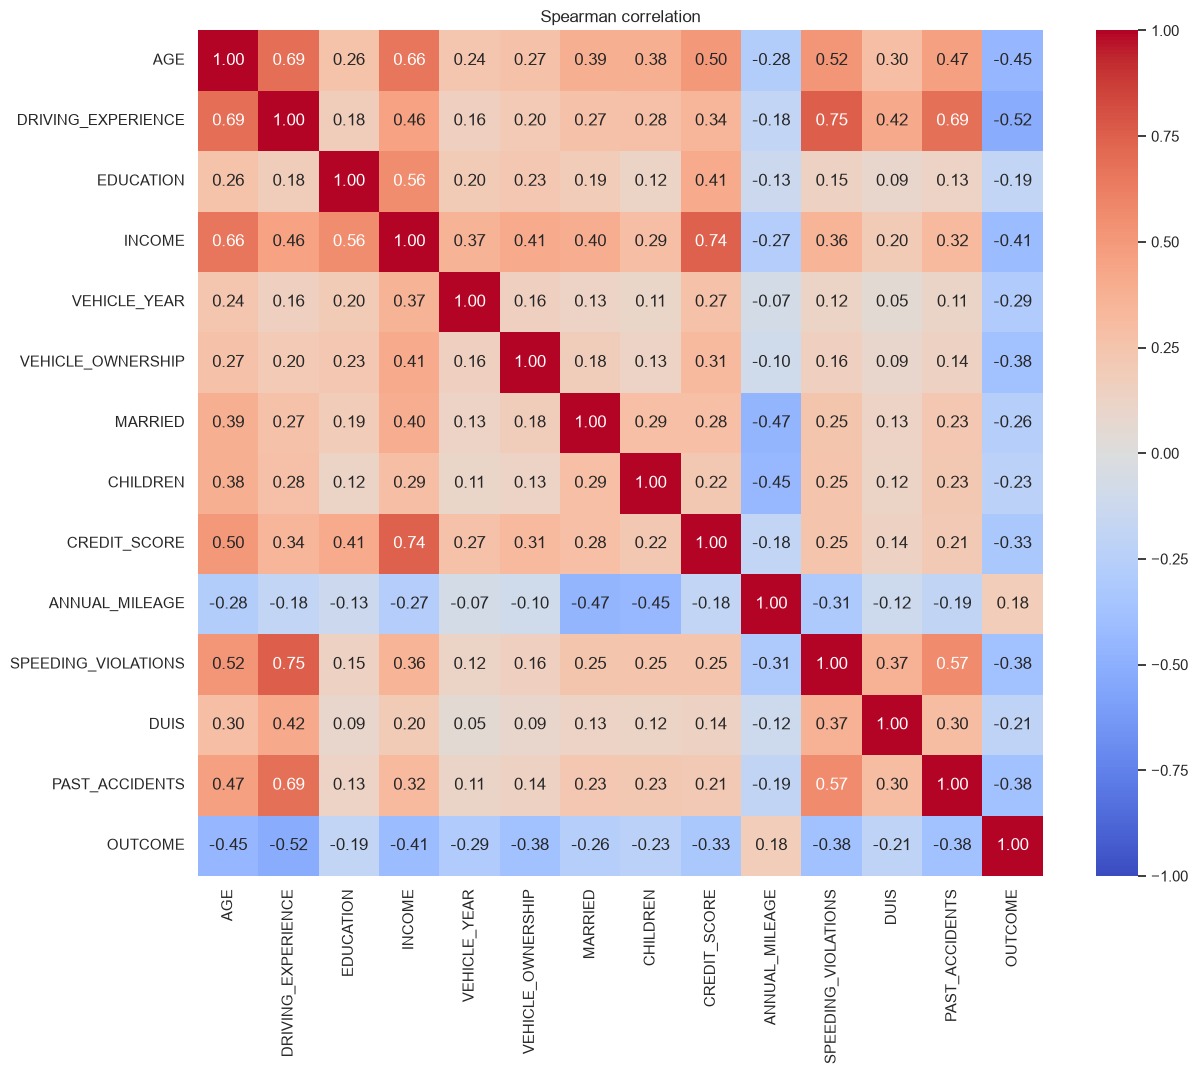

Correlation with target:
DRIVING_EXPERIENCE    -0.519
AGE                   -0.448
INCOME                -0.415
VEHICLE_OWNERSHIP     -0.379
PAST_ACCIDENTS        -0.378
SPEEDING_VIOLATIONS   -0.377
CREDIT_SCORE          -0.327
VEHICLE_YEAR          -0.294
MARRIED               -0.262
CHILDREN              -0.233
DUIS                  -0.205
EDUCATION             -0.186
ANNUAL_MILEAGE         0.183

Feature pairs with |rho| > 0.8 (multicollinearity, not leakage): none


In [16]:
def to_codes(d):
    out = d.copy()
    for c, order in groups["ordinal"].items():
        out[c] = d[c].map({v: i for i, v in enumerate(order)})
    return out

corr_cols = list(groups["ordinal"]) + groups["binary"] + groups["numeric"] + [TARGET]
corr = to_codes(df)[corr_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(0.7 * len(corr_cols) + 3, 0.6 * len(corr_cols) + 2.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman correlation")
savefig("05_correlation_heatmap.png")

print("Correlation with target:")
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).to_string())

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
strong = pairs[(pairs.abs() > 0.8) & ~pairs.index.get_level_values(1).isin([TARGET])]
print("\nFeature pairs with |rho| > 0.8 (multicollinearity, not leakage):",
      "none" if strong.empty else "")
if not strong.empty:
    print(strong.round(3).to_string())

## 3. Missing Values & Cleaning

In [17]:
cleaning_log = {"rows_raw": int(len(raw)), "rows_after_standardisation": int(len(df))}

### 3.1 Duplicates

In [18]:
feat_cols_all = [c for c in df.columns if c != ID_COL]            # features + target, without the ID
feat_only     = [c for c in feat_cols_all if c != TARGET]

dup_report = {
    "exact duplicate rows (all columns)":                   int(df.duplicated().sum()),
    "repeated IDs":                                         int(df[ID_COL].duplicated().sum()) if ID_COL in df else 0,
    "identical profile + outcome (ignoring ID), all values present": int((df.duplicated(subset=feat_cols_all) & df[feat_cols_all].notna().all(axis=1)).sum()),
    "identical profile + outcome (ignoring ID), only because of shared NaNs": int((df.duplicated(subset=feat_cols_all) & df[feat_cols_all].isna().any(axis=1)).sum()),
    "identical profile but DIFFERENT outcome (groups)":     int(df.groupby(feat_only, dropna=False)[TARGET].nunique().gt(1).sum()),
}
display(pd.Series(dup_report, name="count").to_frame())

n0 = len(df)
df = df.drop_duplicates(keep="first")                                # exact duplicates (ID included)
copy_mask = df.duplicated(subset=feat_cols_all) & df[feat_cols_all].notna().all(axis=1)
df = df.loc[~copy_mask]                                              # copies with a different ID (complete rows only)
if ID_COL in df:
    df = df.drop_duplicates(subset=ID_COL, keep="first")           # same ID twice = same customer twice
df = df.reset_index(drop=True)
cleaning_log["duplicates_removed"] = int(n0 - len(df))
print(f"Removed {n0 - len(df):,} duplicate rows -> {len(df):,} rows remain")

,count
exact duplicate rows (all columns),0
repeated IDs,0
"identical profile + outcome (ignoring ID), all values present",0
"identical profile + outcome (ignoring ID), only because of shared NaNs",12
identical profile but DIFFERENT outcome (groups),4


Removed 0 duplicate rows -> 10,000 rows remain


> **Why drop "identical profile + outcome" rows too?** `CREDIT_SCORE` is continuous, so two different customers matching on *every* column is practically impossible when all values are present: those rows are copies. Copies split across train/test are a classic silent leak (the model is tested on rows it has already seen).
> Rows that look identical **only because they share missing values** (pandas treats NaN == NaN) are *not* evidence of a copy, so they are not removed here; section 3.2 handles them as missing values.
> Identical profiles with *different* outcomes (if any are reported above) are label noise; they are reported but kept.

### 3.2 Missing values

In [19]:
n0 = len(df)
rate_before = df[TARGET].mean()

df = df.dropna(subset=[TARGET])                       # a row without a label is useless in every strategy
if MISSING_STRATEGY == "drop":
    df = df.dropna().reset_index(drop=True)
    cleaning_log["rows_removed_missing"] = int(n0 - len(df))
    print(f"MISSING_STRATEGY='drop': removed {n0 - len(df):,} rows with missing values -> {len(df):,} rows remain")
elif MISSING_STRATEGY == "impute":
    df = df.reset_index(drop=True)
    cleaning_log["rows_removed_missing"] = int(n0 - len(df))
    print("MISSING_STRATEGY='impute': rows kept; imputers are fitted on the TRAIN split inside the preprocessor.")
else:
    raise ValueError("MISSING_STRATEGY must be 'drop' or 'impute'")

print(f"Claim rate before: {rate_before:.3%} | after: {df[TARGET].mean():.3%}   (a large shift would mean the removed rows were not random)")
print("Missing values left:", int(df.isna().sum().sum()))

MISSING_STRATEGY='drop': removed 1,851 rows with missing values -> 8,149 rows remain
Claim rate before: 31.330% | after: 31.120%   (a large shift would mean the removed rows were not random)
Missing values left: 0


### 3.3 Validity checks (impossible values)

In [20]:
groups = infer_groups(df)
invalid = pd.Series(False, index=df.index)
rows = []
for c in groups["numeric"]:
    lo, hi = RANGE_RULES.get(c, (0, None))              # default rule: counts / amounts can't be negative
    bad = pd.Series(False, index=df.index)
    if lo is not None: bad |= df[c] < lo
    if hi is not None: bad |= df[c] > hi
    rows.append({"column": c, "min": df[c].min(), "max": df[c].max(), "allowed": f"[{lo}, {hi}]", "invalid_rows": int(bad.sum())})
    invalid |= bad
bad_target = ~df[TARGET].isin([0, 1]); invalid |= bad_target
display(pd.DataFrame(rows).set_index("column"))
print(f"Target values outside {{0,1}}: {int(bad_target.sum())}")

n0 = len(df)
df = df.loc[~invalid].reset_index(drop=True)
cleaning_log["rows_removed_invalid"] = int(n0 - len(df))
print(f"Removed {n0 - len(df)} rows with impossible values")

,min,max,allowed,invalid_rows
column,,,,
CREDIT_SCORE,0.053358,0.960819,"[0, 1]",0
ANNUAL_MILEAGE,2000.000000,22000.000000,"[0, None]",0
SPEEDING_VIOLATIONS,0.000000,22.000000,"[0, None]",0
DUIS,0.000000,6.000000,"[0, None]",0
PAST_ACCIDENTS,0.000000,15.000000,"[0, None]",0


Target values outside {0,1}: 0
Removed 0 rows with impossible values


### 3.4 Fix data types

In [21]:
df[TARGET] = df[TARGET].astype("int64")
for c in infer_groups(df)["binary"] + [c for c in NOMINAL_CODES if c in df]:
    if df[c].notna().all():
        df[c] = df[c].astype("int64")          # 1.0 -> 1, 10238.0 -> 10238
groups = infer_groups(df)
print(df.dtypes.astype(str).to_string())

ID                       int64
AGE                        str
GENDER                     str
RACE                       str
DRIVING_EXPERIENCE         str
EDUCATION                  str
INCOME                     str
CREDIT_SCORE           float64
VEHICLE_OWNERSHIP        int64
VEHICLE_YEAR               str
MARRIED                  int64
CHILDREN                 int64
POSTAL_CODE              int64
ANNUAL_MILEAGE         float64
VEHICLE_TYPE               str
SPEEDING_VIOLATIONS      int64
DUIS                     int64
PAST_ACCIDENTS           int64
OUTCOME                  int64


### 3.5 Outliers (reported, not removed)

In [22]:
rows = []
for c in groups["numeric"]:
    q1, q3 = df[c].quantile([0.25, 0.75]); iqr = q3 - q1
    n_out = int(((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum())
    rows.append({"column": c, "min": df[c].min(), "p50": df[c].median(), "max": df[c].max(),
                 "outliers_IQR": n_out, "pct": round(100 * n_out / len(df), 2)})
display(pd.DataFrame(rows).set_index("column"))

,min,p50,max,outliers_IQR,pct
column,,,,,
CREDIT_SCORE,0.053358,0.526759,0.960819,8,0.10
ANNUAL_MILEAGE,2000.000000,12000.000000,22000.000000,16,0.20
SPEEDING_VIOLATIONS,0.000000,0.000000,22.000000,493,6.05
DUIS,0.000000,0.000000,6.000000,1543,18.93
PAST_ACCIDENTS,0.000000,0.000000,15.000000,231,2.83


Values inside the valid range are **kept**: in insurance data a high-mileage driver or a customer with several violations is exactly the kind of signal the model should learn from, and capping them would hide it. `StandardScaler` (section 4) keeps their influence on the network reasonable.

### 3.6 Data-leakage audit

Three automatic tests, then a manual availability review:
1. **Identifier test** – a non-float column with one unique value per row carries no information about risk (and lets a network memorise rows).
2. **Target-name test** – feature names that look derived from the label (`claim`, `outcome`, `payout`, ...).
3. **Single-feature AUC** – how well each feature *alone* ranks the outcome. Real risk factors give modest AUCs; an AUC close to 1 means the feature almost *is* the label.

In [23]:
def single_feature_auc(d, col):
    """AUC of one feature alone. Categories are scored by their own claim rate (no model needed)."""
    s, y = d[col], d[TARGET]
    m = s.notna()
    if col in groups["ordinal"] or col in groups["nominal"]:
        score = y[m].groupby(s[m]).transform("mean")
    else:
        score = s[m]
    auc = roc_auc_score(y[m], score)
    return max(auc, 1 - auc)

feat_now = [c for c in df.columns if c != TARGET]
kind = {**{c: "ordinal" for c in groups["ordinal"]}, **{c: "nominal" for c in groups["nominal"]},
        **{c: "binary" for c in groups["binary"]}, **{c: "numeric" for c in groups["numeric"]}}

audit = pd.DataFrame({
    "type":     [kind.get(c, "id") for c in feat_now],
    "n_unique": [df[c].nunique() for c in feat_now],
    "AUC":      [single_feature_auc(df, c) if c in kind else np.nan for c in feat_now],
}, index=feat_now)

audit["identifier"]  = [(df[c].nunique() == len(df)) and not pd.api.types.is_float_dtype(df[c]) for c in feat_now]
audit["target_name"] = audit.index.str.contains(r"outcome|claim|target|label|payout|settle", case=False)
audit["suspicious_auc"] = audit["AUC"] > LEAK_AUC
audit["FLAG"] = audit[["identifier", "target_name", "suspicious_auc"]].any(axis=1)
audit.sort_values("AUC", ascending=False).round(3)

,type,n_unique,AUC,identifier,target_name,suspicious_auc,FLAG
DRIVING_EXPERIENCE,ordinal,4,0.808,False,False,False,False
AGE,ordinal,4,0.767,False,False,False,False
INCOME,ordinal,4,0.741,False,False,False,False
SPEEDING_VIOLATIONS,numeric,21,0.719,False,False,False,False
PAST_ACCIDENTS,numeric,15,0.714,False,False,False,False
CREDIT_SCORE,numeric,8149,0.702,False,False,False,False
VEHICLE_OWNERSHIP,binary,2,0.691,False,False,False,False
VEHICLE_YEAR,ordinal,2,0.645,False,False,False,False
MARRIED,binary,2,0.637,False,False,False,False
CHILDREN,binary,2,0.615,False,False,False,False


In [24]:
auto_leaky = audit.index[audit["FLAG"]].tolist()
LEAKY_COLS = sorted(set(auto_leaky) | ({ID_COL} & set(df.columns)))
print("Leakage / non-informative columns to drop :", LEAKY_COLS)
print("Highest single-feature AUC among kept features:",
      audit.drop(index=LEAKY_COLS)["AUC"].idxmax(), round(audit.drop(index=LEAKY_COLS)["AUC"].max(), 3),
      f"(threshold {LEAK_AUC})")

Leakage / non-informative columns to drop : ['ID']
Highest single-feature AUC among kept features: DRIVING_EXPERIENCE 0.808 (threshold 0.85)


**Manual availability review** – a feature is safe only if it is known *at quote time*, before the outcome exists.

| Feature(s) | Verdict | Reason |
|---|---|---|
| `ID` | ❌ drop | Row identifier: no risk information, enables memorisation. |
| `OUTCOME` | target | The label itself; never a feature. |
| `AGE`, `GENDER`, `RACE`, `EDUCATION`, `INCOME`, `MARRIED`, `CHILDREN`, `POSTAL_CODE` | ✅ keep | Customer attributes known when the policy is quoted. `POSTAL_CODE` is a *category*, so it is one-hot encoded, never scaled as a number. |
| `VEHICLE_OWNERSHIP`, `VEHICLE_YEAR`, `VEHICLE_TYPE`, `ANNUAL_MILEAGE`, `CREDIT_SCORE` | ✅ keep | Vehicle / customer data known at quote time. |
| `DRIVING_EXPERIENCE` | ✅ keep | Strongest legitimate predictor; highly correlated with `AGE` (see 2.6), which is multicollinearity, not leakage. |
| `SPEEDING_VIOLATIONS`, `DUIS`, `PAST_ACCIDENTS` | ⚠️ keep, **confirm definition** | Valid only if they are the *historical record before the policy period*. If `PAST_ACCIDENTS` included the accident behind the claim, it would be leakage. The dataset gives no timestamps, so this can't be verified from the file alone. |
| `RACE`, `GENDER` | ⚠️ keep by default | Not leakage, but protected attributes (fairness / legality in underwriting). Set `DROP_SENSITIVE = True` to remove them; mention it in *Limitations*. |

In [25]:
DROP_COLS = list(LEAKY_COLS)
if DROP_SENSITIVE:
    DROP_COLS += [c for c in SENSITIVE_COLS if c in df.columns and c not in DROP_COLS]

FEATURE_COLS = [c for c in df.columns if c not in DROP_COLS + [TARGET]]
print("Dropped columns :", DROP_COLS)
print(f"Kept features ({len(FEATURE_COLS)}):", FEATURE_COLS)

cleaning_log["rows_clean"] = int(len(df))
cleaning_log["rows_removed_total"] = int(len(raw) - len(df))
print(f"\nRows: raw {len(raw):,} -> clean {len(df):,}  (removed {len(raw) - len(df):,}, {(len(raw) - len(df)) / len(raw):.1%})")

Dropped columns : ['ID']
Kept features (17): ['AGE', 'GENDER', 'RACE', 'DRIVING_EXPERIENCE', 'EDUCATION', 'INCOME', 'CREDIT_SCORE', 'VEHICLE_OWNERSHIP', 'VEHICLE_YEAR', 'MARRIED', 'CHILDREN', 'POSTAL_CODE', 'ANNUAL_MILEAGE', 'VEHICLE_TYPE', 'SPEEDING_VIOLATIONS', 'DUIS', 'PAST_ACCIDENTS']

Rows: raw 10,000 -> clean 8,149  (removed 1,851, 18.5%)


## 4. Encoding & Scaling (ColumnTransformer)

Rules per feature type:

| Type | Treatment |
|---|---|
| numeric (mileage, credit score, counts) | median imputer → `StandardScaler` |
| ordinal (age band, experience, education, income, vehicle year) | explicit order → `OrdinalEncoder` → `StandardScaler` |
| binary (0/1) | kept as 0/1 |
| nominal (gender, race, postal code, ...) | `OneHotEncoder(handle_unknown="ignore")` |

> ⚠️ The transformer is only **defined** here. It is **fitted in section 5 after the split, on the training rows only** — fitting a scaler on the whole dataset would leak validation/test statistics into training.

In [26]:
groups = infer_groups(df[FEATURE_COLS + [TARGET]])

def build_preprocessor(g):
    steps = []
    if g["numeric"]:
        steps.append(("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                                       ("scaler", StandardScaler())]), g["numeric"]))
    if g["ordinal"]:
        cols = list(g["ordinal"])
        steps.append(("ord", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                       ("encoder", OrdinalEncoder(categories=[g["ordinal"][c] for c in cols],
                                                                  handle_unknown="use_encoded_value", unknown_value=-1)),
                                       ("scaler", StandardScaler())]), cols))
    if g["binary"]:
        steps.append(("bin", SimpleImputer(strategy="most_frequent"), g["binary"]))
    if g["nominal"]:
        steps.append(("nom", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                       ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), g["nominal"]))
    return ColumnTransformer(steps, remainder="drop")

preprocessor = build_preprocessor(groups)
set_config(display="diagram")
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('ord', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n

## 5. Train / Val / Test Split (stratified, SEED)

In [27]:
y_all = df[TARGET].to_numpy()
idx = np.arange(len(df))

# 70 / 15 / 15, stratified on the target, reproducible with SEED
idx_trainval, idx_test = train_test_split(idx, test_size=TEST_SIZE, stratify=y_all, random_state=SEED)
idx_train, idx_val = train_test_split(idx_trainval, test_size=VAL_SIZE / (1 - TEST_SIZE),
                                      stratify=y_all[idx_trainval], random_state=SEED)

X_train_raw, X_val_raw, X_test_raw = (df.iloc[i][FEATURE_COLS] for i in (idx_train, idx_val, idx_test))
y_train, y_val, y_test = (y_all[i] for i in (idx_train, idx_val, idx_test))

# Fit ONLY on train, then transform all three splits
preprocessor.fit(X_train_raw)
X_train = preprocessor.transform(X_train_raw).astype("float32")
X_val   = preprocessor.transform(X_val_raw).astype("float32")
X_test  = preprocessor.transform(X_test_raw).astype("float32")
y_train, y_val, y_test = (a.astype("int64") for a in (y_train, y_val, y_test))

FEATURE_NAMES = [n.split("__", 1)[-1] for n in preprocessor.get_feature_names_out()]
print(f"train {X_train.shape} | val {X_val.shape} | test {X_test.shape} | features after encoding: {len(FEATURE_NAMES)}")

train (5703, 23) | val (1223, 23) | test (1223, 23) | features after encoding: 23


In [28]:
# ---- sanity checks on the split ----
assert len(idx_train) + len(idx_val) + len(idx_test) == len(df)
assert not (set(idx_train) & set(idx_val)) and not (set(idx_train) & set(idx_test)) and not (set(idx_val) & set(idx_test))
for name, a in [("X_train", X_train), ("X_val", X_val), ("X_test", X_test)]:
    assert not np.isnan(a).any(), f"NaN in {name}"

summary = pd.DataFrame({
    "rows":       [len(y_train), len(y_val), len(y_test)],
    "share":      [len(y_train) / len(df), len(y_val) / len(df), len(y_test) / len(df)],
    "claim_rate": [y_train.mean(), y_val.mean(), y_test.mean()],
}, index=["train", "val", "test"]).round(4)
display(summary)

cross = pd.concat([X_train_raw, X_val_raw, X_test_raw]).duplicated().sum()
print("Feature-identical rows across/within splits (should be ~0 after de-duplication):", int(cross))

scaled = [i for i, n in enumerate(FEATURE_NAMES) if n in groups["numeric"]]
if scaled:
    print("Train mean of scaled numeric columns (should be ~0):", np.abs(X_train[:, scaled].mean(axis=0)).max().round(6))
    print("Val   mean of scaled numeric columns (NOT exactly 0 = val statistics were not used for fitting):",
          np.abs(X_val[:, scaled].mean(axis=0)).max().round(4))

,rows,share,claim_rate
train,5703,0.6998,0.3111
val,1223,0.1501,0.3115
test,1223,0.1501,0.3115


Feature-identical rows across/within splits (should be ~0 after de-duplication): 0
Train mean of scaled numeric columns (should be ~0): 0.0
Val   mean of scaled numeric columns (NOT exactly 0 = val statistics were not used for fitting): 0.0622


## 6. Class Imbalance Check (class weights)

,train,val,test
no claim (0),3929,842,842
claim (1),1774,381,381


Minority-class share (train): 31.1%   |   imbalance ratio: 2.21 : 1
class_weight for model.fit(...): {0: 0.726, 1: 1.607}


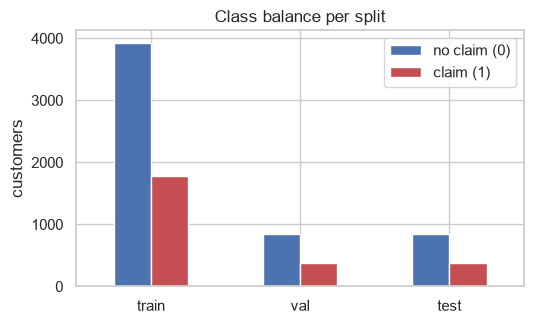

In [29]:
classes = np.array([0, 1])
weights = compute_class_weight("balanced", classes=classes, y=y_train)
class_weight = {int(c): float(w) for c, w in zip(classes, weights)}      # computed on TRAIN only

counts = pd.DataFrame({s: np.bincount(y, minlength=2) for s, y in [("train", y_train), ("val", y_val), ("test", y_test)]},
                      index=["no claim (0)", "claim (1)"])
display(counts)

minority_share = y_train.mean() if y_train.mean() < 0.5 else 1 - y_train.mean()
print(f"Minority-class share (train): {minority_share:.1%}   |   imbalance ratio: {(1 - minority_share) / minority_share:.2f} : 1")
print("class_weight for model.fit(...):", {k: round(v, 3) for k, v in class_weight.items()})

fig, ax = plt.subplots(figsize=(5.5, 3.4))
counts.T.plot.bar(ax=ax, color=["#4C72B0", "#C44E52"], rot=0)
ax.set_title("Class balance per split"); ax.set_ylabel("customers")
savefig("06_class_balance.png")

**Reading this:** if the minority share is clearly below 50% (but not extreme), plain *accuracy* is misleading. Notebooks 02–03 should (a) pass `class_weight` from `data/processed/class_weights.json` to `model.fit`, and (b) judge models with Precision / Recall / F1 / ROC-AUC, as the README already requires. No resampling is applied: the validation and test sets keep the real class ratio.

## 7. Save Splits (`data/processed/*.npy`) & Preprocessor (`models/preprocessor.pkl`)

In [30]:
# 1) frozen splits (names must match load_splits() in the shared setup)
for name, arr in [("X_train", X_train), ("X_val", X_val), ("X_test", X_test),
                  ("y_train", y_train), ("y_val", y_val), ("y_test", y_test)]:
    np.save(f"{PROCESSED_DIR}/{name}.npy", arr)

# 2) fitted preprocessor (sklearn built-ins only, so it can be unpickled from src/inference.py)
joblib.dump(preprocessor, PREPROCESSOR_PKL)

# 3) helper files for the rest of the team
with open(f"{PROCESSED_DIR}/class_weights.json", "w") as f:
    json.dump(class_weight, f, indent=2)
with open(f"{PROCESSED_DIR}/feature_names.json", "w") as f:
    json.dump(FEATURE_NAMES, f, indent=2)

meta = {
    "seed": SEED, "target": TARGET, "id_column": ID_COL,
    "missing_strategy": MISSING_STRATEGY, "split": {"train": 1 - TEST_SIZE - VAL_SIZE, "val": VAL_SIZE, "test": TEST_SIZE},
    "dropped_columns": DROP_COLS,
    "raw_input_columns": FEATURE_COLS,
    "column_groups": {"numeric": groups["numeric"], "ordinal": groups["ordinal"],
                      "binary": groups["binary"], "nominal": groups["nominal"]},
    "allowed_values": {c: sorted(df[c].dropna().unique().tolist()) for c in list(groups["ordinal"]) + groups["nominal"]},
    "input_notes": ["predict_risk() input = ONE row with exactly `raw_input_columns` (no ID, no OUTCOME).",
                    "Text values are lower-case/trimmed as in `allowed_values`; POSTAL_CODE and 0/1 columns are integers.",
                    "Unknown categories are ignored by one-hot and mapped to -1 for ordinal columns."],
    "n_features_after_encoding": len(FEATURE_NAMES),
    "rows": {**cleaning_log, "train": int(len(y_train)), "val": int(len(y_val)), "test": int(len(y_test))},
    "class_weight": class_weight,
    "versions": {"scikit-learn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__},
}
with open(f"{PROCESSED_DIR}/preprocessor_meta.json", "w") as f:
    json.dump(meta, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))

# 4) raw (cleaned) rows of every split, same row order as X_*.npy -> for error analysis in notebook 03
keep = ([ID_COL] if ID_COL in df.columns else []) + FEATURE_COLS + [TARGET]
pd.concat([df.iloc[i][keep].assign(split=s) for s, i in [("train", idx_train), ("val", idx_val), ("test", idx_test)]]) \
  .to_csv(f"{PROCESSED_DIR}/splits_raw.csv", index=False)

print("Saved:", sorted(os.listdir(PROCESSED_DIR)), "+", PREPROCESSOR_PKL)

Saved: ['.gitkeep', 'X_test.npy', 'X_train.npy', 'X_val.npy', 'class_weights.json', 'feature_names.json', 'preprocessor_meta.json', 'splits_raw.csv', 'y_test.npy', 'y_train.npy', 'y_val.npy'] + models/preprocessor.pkl


### Verify the saved files (reload exactly like the other notebooks will)

In [31]:
X_tr, X_v, X_te, y_tr, y_v, y_te = load_splits()                  # shared helper from the setup cell
assert np.array_equal(X_tr, X_train) and np.array_equal(X_te, X_test) and np.array_equal(y_te, y_test)
assert X_tr.shape[1] == X_v.shape[1] == X_te.shape[1] == len(FEATURE_NAMES)
assert not (np.isnan(X_tr).any() or np.isnan(X_v).any() or np.isnan(X_te).any())

pp = joblib.load(PREPROCESSOR_PKL)
assert np.allclose(pp.transform(X_test_raw), X_test, atol=1e-5)    # raw rows -> same features the model was trained on

# single-customer inference path (what predict_risk() will do)
one = X_test_raw.iloc[[0]]
print("One raw customer ->", pp.transform(one).shape, "features")
print("\nAll checks passed.")

One raw customer -> (1, 23) features

All checks passed.


## ✅ Handoff to Members 2–4

```python
# in notebooks 02 / 03
X_train, X_val, X_test, y_train, y_val, y_test = load_splits()
class_weight = {int(k): v for k, v in json.load(open(f"{PROCESSED_DIR}/class_weights.json")).items()}
input_dim = X_train.shape[1]
model.fit(X_train, y_train, validation_data=(X_val, y_val), class_weight=class_weight, ...)
```

* **Never re-split or re-fit the preprocessor** (team rule 4). Use `models/preprocessor.pkl` to transform new data.
* `predict_risk()` (notebook 04): build a one-row `DataFrame` with the columns in `preprocessor_meta.json → raw_input_columns`, then call `preprocessor.transform(...)`. Allowed category values are listed in the same file.
* `splits_raw.csv` holds the readable rows behind each `X_*.npy` row (same order) for error analysis.
* Pickled with the scikit-learn version recorded in `preprocessor_meta.json → versions`; use the same version to load it.
* Figures for the slides are in `reports/figures/` (`01_` … `06_`).